In [1]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy.ma as ma
import pandas as pd 
import skimage as sk
import scipy.ndimage as nd
import numpy as np
from ROOT import TLine, TLegend
from scipy.optimize import curve_fit

# import ROOT

import sys
import os
## ===== Así se importan las funciones de arhcivos en otras direcciones === ###
module_path = os.path.abspath('../functions') # Adjust relative path as needed
# # Or use an absolute path: module_path = '/home/your_user/projects/utils'

if module_path not in sys.path:
    sys.path.append(module_path)

from functionsNEW import *
# from MCM_Analysis.functions import *

def gaussian(x, a, mean, sigma):
    return a * np.exp(-((x - mean)**2 / (2 * sigma**2)))

# def Gaussian2(x,m1,s1,g1,a1, m2, s2, g2, a2): #data, mean, sigma, gain, height1, heigth2
#     return a1*np.exp(-1/2*((x-m1-g1)/s1)**2) + a2*np.exp(-1/2*((x-m2-g2)/s2)**2)

def Gaussian2(x,m,s,g,a1,a2): #data, mean, sigma, gain, height1, heigth2
    return a1*np.exp(-1/2*((x-m)/s)**2)+a2*np.exp(-1/2*((x-m-g)/s)**2)


def EnergySpectrum(x, N):
    return N * np.sin(x)*np.cos(x)**3

# print(time.time())
# print(time.gmtime(0))

In [2]:
plt.rcParams.update({
    "image.origin": "lower",
    "image.aspect": 1,
    #"text.usetex": True,
    "grid.alpha": .5,
    "axes.linewidth": 3,
    "lines.linewidth" : 1,
    "font.size":    15.0,
    "xaxis.labellocation": 'right',  # alignment of the xaxis label: {left, right, center}
    "yaxis.labellocation": 'top',  # alignment of the yaxis label: {bottom, top, center}
    "xtick.top":           True ,  # draw ticks on the top side
    "xtick.major.size":    8    ,# major tick size in points
    "xtick.minor.size":    4      ,# minor tick size in points
    "xtick.direction":     'in',
    "xtick.minor.visible": True,
    "ytick.right":           True ,  # draw ticks on the top side
    "ytick.major.size":    8    ,# major tick size in points
    "ytick.minor.size":    4      ,# minor tick size in points
    "ytick.direction":     'in',
    "ytick.minor.visible": True,
    "ytick.major.width":   2   , # major tick width in points
    "ytick.minor.width":   1 ,
    "xtick.major.width":   2   , # major tick width in points
    "xtick.minor.width":   1 ,
    "legend.framealpha": 0 ,
    "legend.loc": 'best',

})

Colormap = 'jet'

Filename: ../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_470.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       6   ()      
  1  CCD01         1 ImageHDU       174   (500, 500)   float32   
  2  CCD02         1 ImageHDU       174   (500, 500)   float32   
  3  CCD03         1 ImageHDU       174   (500, 500)   float32   
  4  CCD04         1 ImageHDU       172   (500, 500)   float32   
  5  CCD05         1 ImageHDU       174   (500, 500)   float32   
  6  CCD06         1 ImageHDU       174   (500, 500)   float32   
  7  CCD07         1 ImageHDU       172   (500, 500)   float32   
  8  CCD08         1 ImageHDU       174   (500, 500)   float32   
  9  CCD09         1 ImageHDU       172   (500, 500)   float32   
 10  CCD10         1 ImageHDU       174   (500, 500)   float32   
 11  CCD11         1 ImageHDU       172   (500, 500)   float32   
 12  CCD12         1 ImageHDU       174   (50

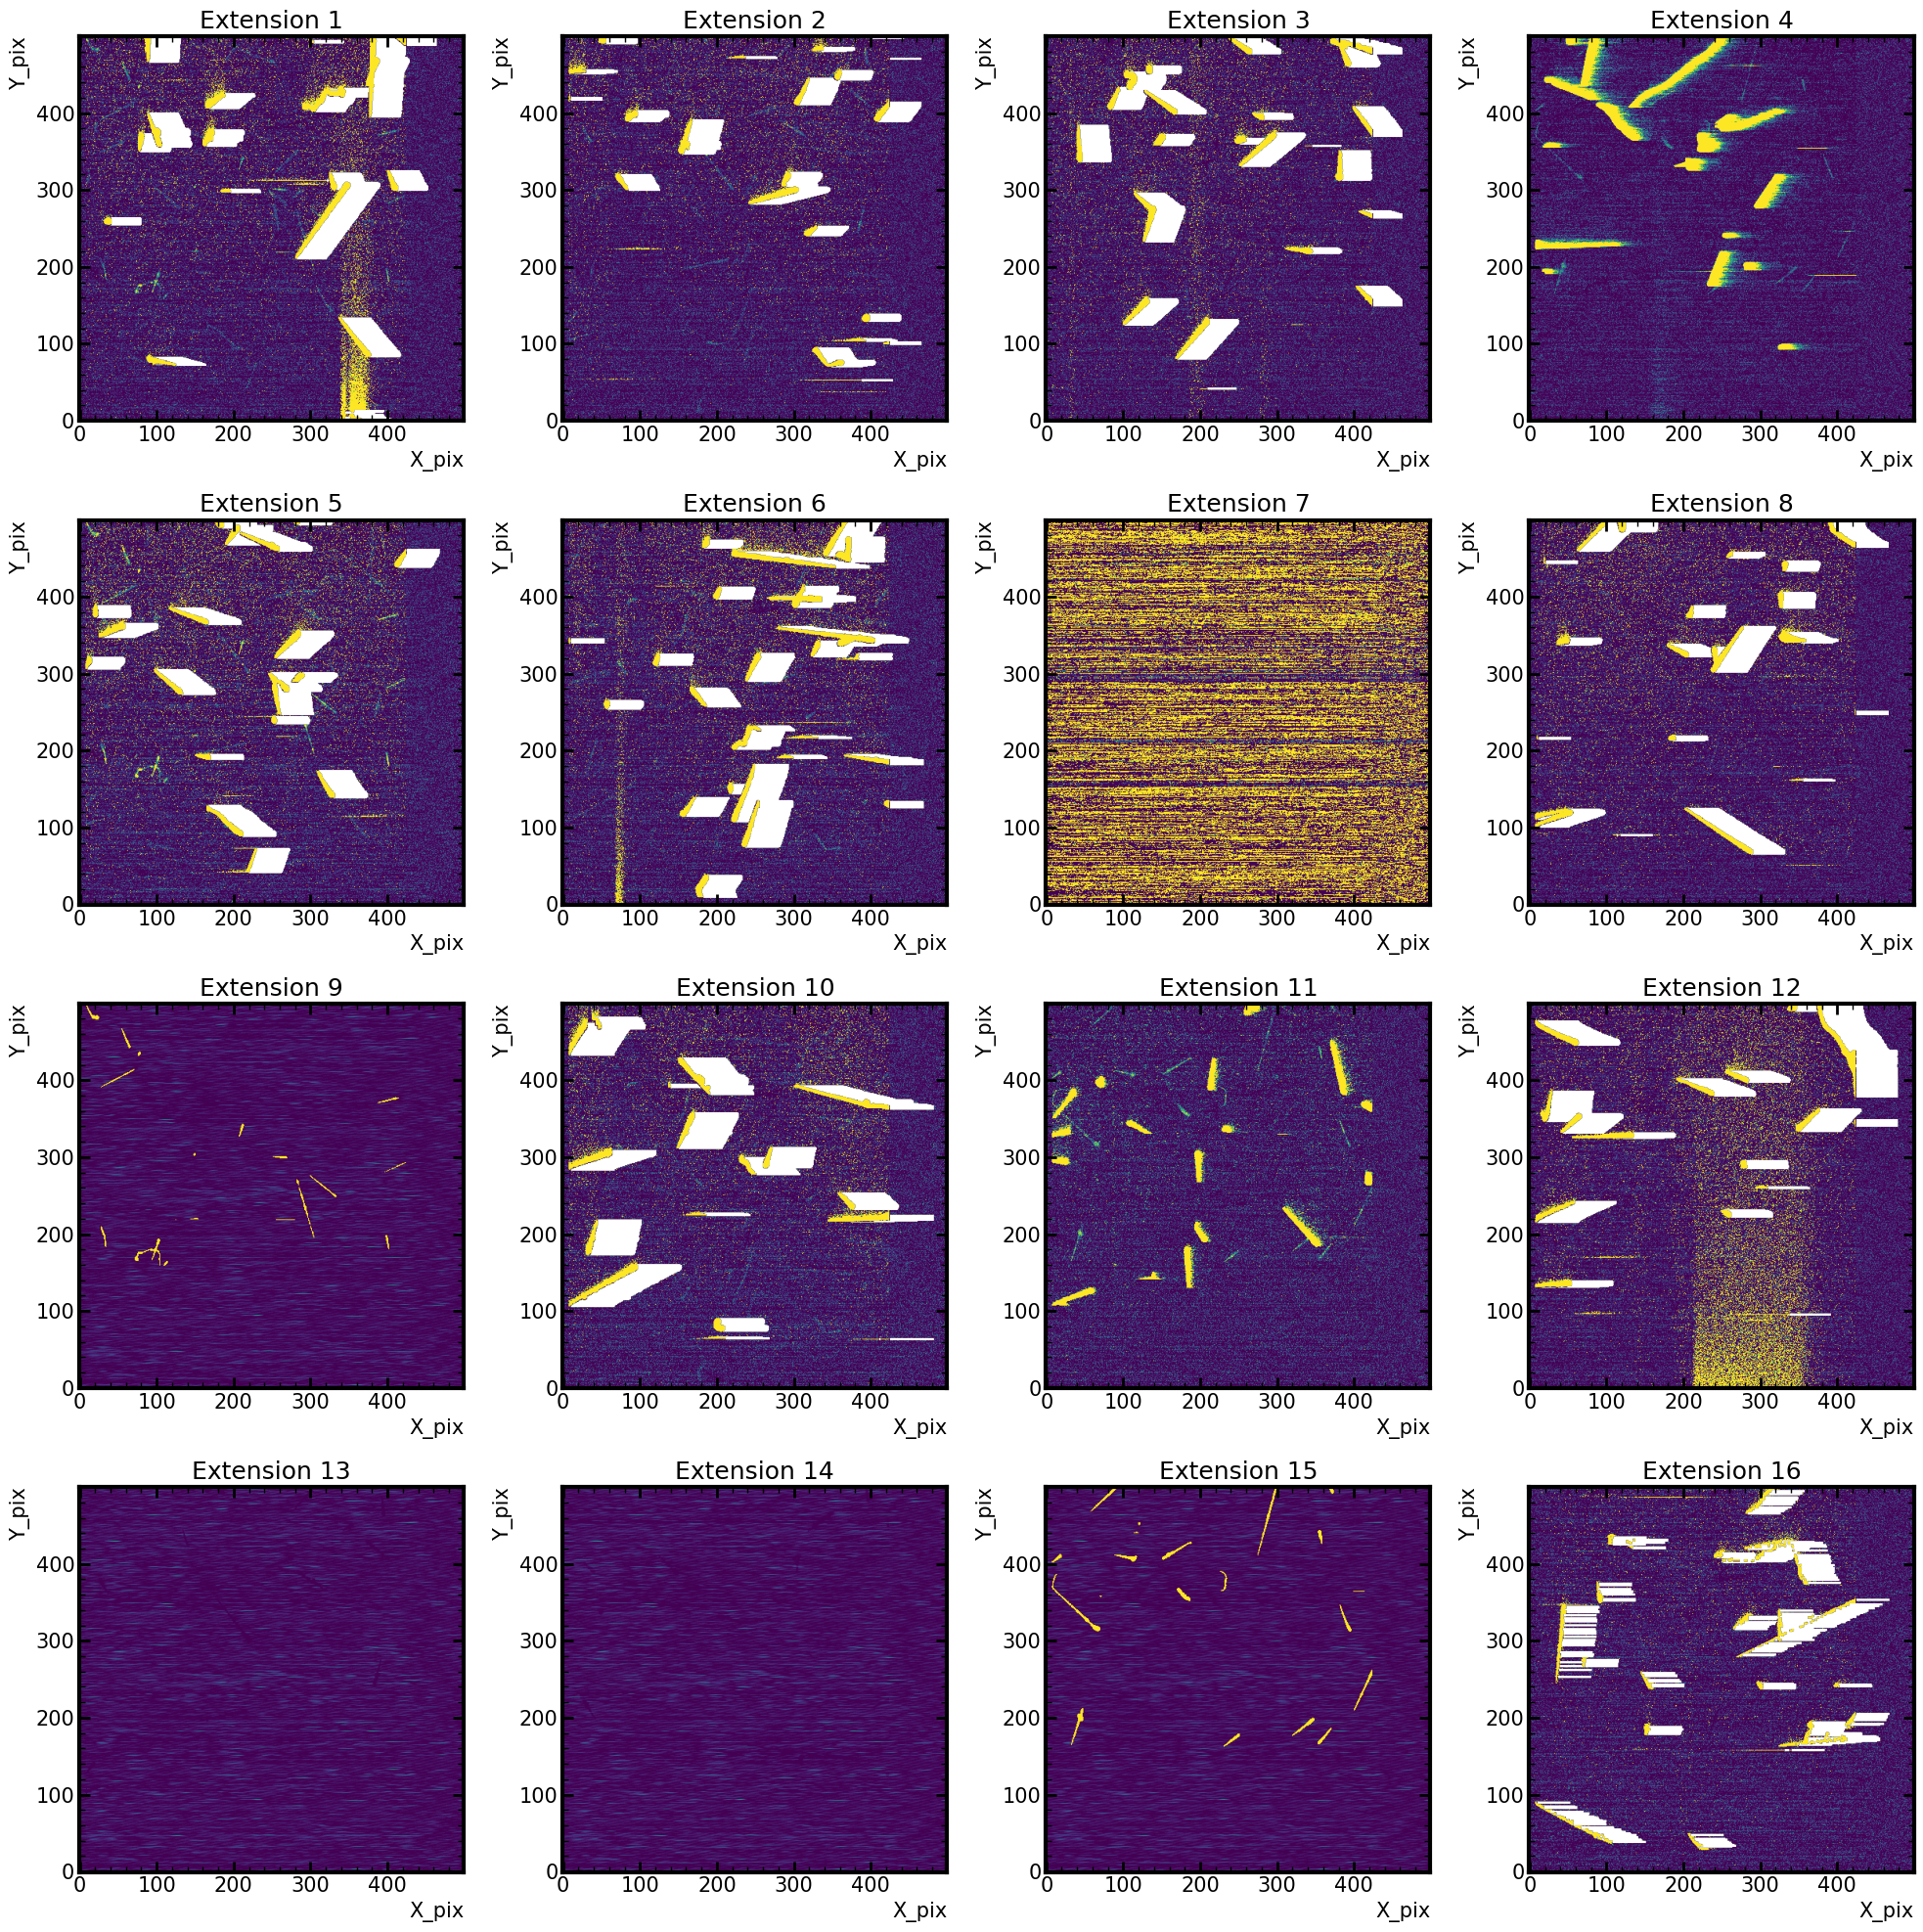

In [3]:
# path = '../../images/CONNIE_MCM/RUN_214/calib_equalized_demuxed_runID214_MCM_NROW500_ANSAMP500_EXP0_1000.fits'
path = '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_470.fits'

# path = '/home/bruce/Downloads/proc_skp_m_009_microchip_T_170_Vv82_NSAMP_324_NROW_100_NCOL_700.fits'

Colormap = 'jet'

hdu_list = fits.open(path)
print("Info: ", hdu_list.info())
print('----------------')
# hdu_list[0].header
list_gains = []

fig, axs = plt.subplots(4, 4, figsize=[20, 20])
for i in range(1,17):
    row = (i - 1) // 4
    col = (i - 1) % 4
    ax = axs[row, col]

    ax.imshow(hdu_list[i].data,vmin = 0, vmax = 1)
    ax.set_title(f'Extension {i}')
    ax.set_ylabel('Y_pix')
    ax.set_xlabel('X_pix')

    # display(hdu_list[i].header)
    list_gains.append(hdu_list[i].header["GAIN_RUN"])

    
plt.tight_layout()
plt.show()




In [4]:
# Choose an extension, write the number directly
extension = 2
x_max = 430
y_max = 500
border = 10

activeArea = hdu_list[extension].data[border:y_max-border, border:x_max] # Without the border
oScan = hdu_list[extension].data[border:y_max-border, x_max:]
header = hdu_list[extension].header

display(header)
##### Sigma en e- ####
Gain = list_gains[extension - 1] # ADU/e
Sigma = 0.18 # e- ------- This images doesn't have the sigma yet.

print(f"Gain: {Gain} ADU/e-")
print(f"Sigma: {Sigma} e-")


XTENSION= 'IMAGE   '           / Image extension                                
BITPIX  =                  -32 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                  500                                                  
NAXIS2  =                  500                                                  
PCOUNT  =                    0 / number of parameters                           
GCOUNT  =                    1 / number of groups                               
ANSAMP  = '500     '           / Smart sequencer variable                       
CCDNCOL = '2148    '           / Smart sequencer variable                       
CCDNPRES= '7       '           / Smart sequencer variable                       
CCDNROW = '2556    '           / Smart sequencer variable                       
NCOL    = '500     '           / Smart sequencer variable                       
NCOL1   = '424     '        

Gain: 706.0535554368424 ADU/e-
Sigma: 0.18 e-


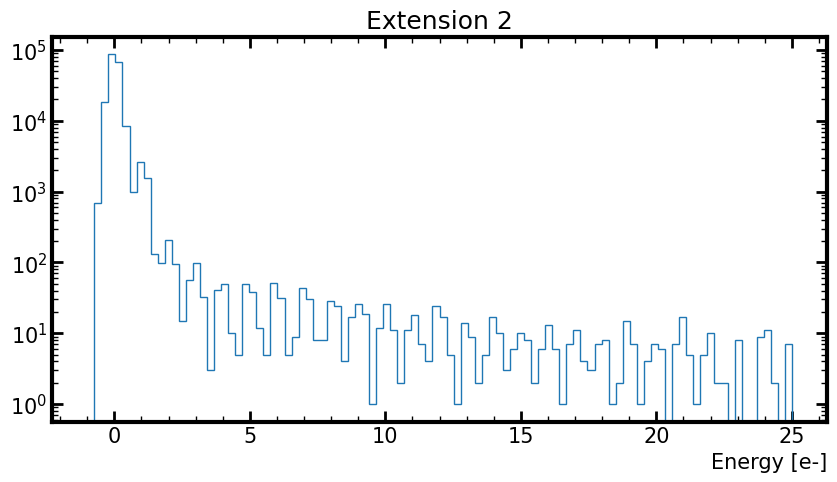

In [5]:
fig, axs = plt.subplots(figsize=[10,5])
axs.hist(activeArea.flatten(), range=(-1,25), bins=100, histtype="step")
# axs.hist(oScan.flatten(), range=(-1,2.5), bins=100, histtype="step")
axs.set_xlabel('Energy [e-]')
axs.set_title(f"Extension {extension}")
axs.set_yscale('log')

plt.show()

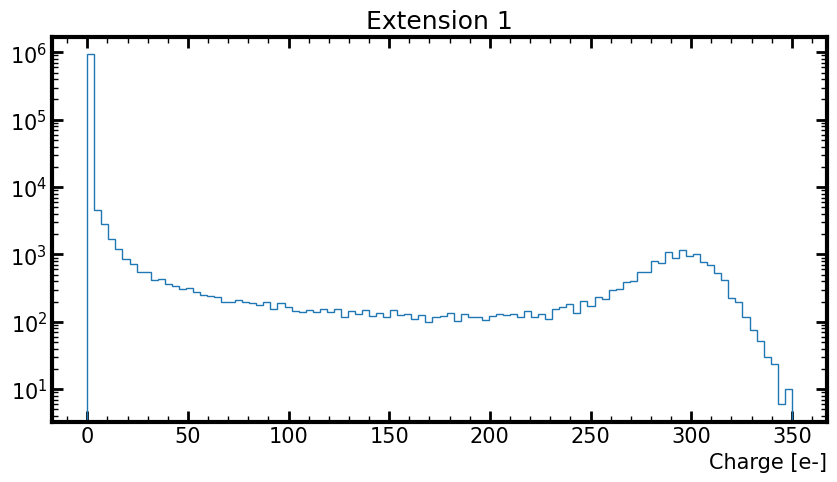

In [6]:
path_imgs = ['../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_470.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_471.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_472.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_473.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_474.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_475.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_476.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_477.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_478.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_479.fits']
extension = 1
x_max = 430
y_max = 500
border = 10

list_active_area = []
for path in path_imgs:
    hdu_list = fits.open(path)
    
    activeArea = hdu_list[extension].data[border:y_max-border, border:x_max] # Without the border
    # oScan = hdu_list[extension].data[border:y_max-border, x_max:]
    header = hdu_list[extension].header

    list_active_area.append(activeArea.flatten())

combined_data = np.array(list_active_area)
# print("Shape of combined data:", combined_data.shape)

fig, axs = plt.subplots(figsize=[10,5])
axs.hist(combined_data.flatten(), range=(0,350), bins=100, histtype="step")
# axs.hist(oScan.flatten(), range=(-1,2.5), bins=100, histtype="step")
axs.set_xlabel('Charge [e-]')
axs.set_title(f"Extension {extension}")
axs.set_yscale('log')

plt.show()


In [7]:
Bins = 100
Bins_fit = Bins
# Range_fit = [-100, 400]

data = combined_data.flatten()
max_value = max(data)
if extension == 1:
    max_value = 350
    
h3=TH1F("histogram", f"Active Area Charge Distribution (Ext {extension})",Bins_fit, -2, max_value+10)
# h3.AddDirectory(False)
for pixel_value in data.flatten():
    # if not np.ma.is_masked(pixel_value):
    h3.Fill(pixel_value)
    #print(pixel_value)

c1=TCanvas()
c1.SetLogy()
c1.SetGrid()
h3.SetStats(0)
h3.GetXaxis().SetTitle("Charge [e-]")
h3.Draw()
c1.Draw()

max_bin = h3.GetMaximumBin();

interface1 = 121
interface2 = 200

range_area1 = [max_bin+4,interface1]
range_area2 = [range_area1[1]+3,interface2]
range_area3 = [range_area2[1]+3,max_value]

first_bin1 = h3.GetXaxis().FindBin(range_area1[0])
last_bin1 =  h3.GetXaxis().FindBin(range_area1[1])

first_bin2 = h3.GetXaxis().FindBin(range_area2[0])
last_bin2 =  h3.GetXaxis().FindBin(range_area2[1])

first_bin3 = h3.GetXaxis().FindBin(range_area3[0])
last_bin3 =  h3.GetXaxis().FindBin(range_area3[1])
# print(f"Selected range 1: {first_bin, last_bin}")

area1 = h3.Integral(first_bin1, last_bin1)
area2 = h3.Integral(first_bin2, last_bin2)
area3 = h3.Integral(first_bin3, last_bin3)

shaded1 = h3.Clone("shaded1")
shaded2 = h3.Clone("shaded2")
shaded3 = h3.Clone("shaded3")

shaded1.GetXaxis().SetRangeUser(range_area1[0], range_area1[1])
shaded2.GetXaxis().SetRangeUser(range_area2[0], range_area2[1])
shaded3.GetXaxis().SetRangeUser(range_area3[0], range_area3[1])

# Style and draw overlay
shaded1.SetFillColor(3) 
shaded1.SetFillStyle(3001)  # Semi-transparent style
shaded1.Draw("HIST SAME")

shaded2.SetFillColor(94)  
shaded2.SetFillStyle(3001)  # Semi-transparent style
shaded2.Draw("HIST SAME")

shaded3.SetFillColor(2)  
shaded3.SetFillStyle(3001)  # Semi-transparent style
shaded3.Draw("HIST SAME")

# high = fgaus.GetParameters()[0]
# en_scape = theo_peak
# line1 = TLine(en_scape, 0, en_scape, high)
# line1.SetLineColor(1)
# line1.SetLineWidth(2)
# line1.Draw()
total_Area = area1 + area2+ area3
percet1 = round((area1/total_Area)*100,1)
percet2 = round((area2/total_Area)*100,1)
percet3 = round((area3/total_Area)*100,1)
print(f"Total Area: {total_Area}")
print(f"Area OKAY: {area1} ({percet1}%)")
print(f"Area BAD: {area2} ({percet2}%)")
print(f"Area WARNING: {area3} ({percet3}%)")


leg = TLegend(0.55,0.75,0.9,0.9)
# leg.AddEntry(h3, "Data", "PL")
# leg.AddEntry(h3, r"cal = 196.881 \pm 7.802 ADU/e")
leg.AddEntry(shaded1, f"Functional Area", "HF")
leg.AddEntry(shaded2, f"Bad Area (<0.5 diff)", "HF")
leg.AddEntry(shaded3, f"Non-functional Area (>= 0.5 diff)", "HF")
# leg.AddEntry(line1, f"Theoretical Value: {en_scape}", "L")
leg.Draw()


Total Area: 44103.0
Area OKAY: 26400.0 (59.9%)
Area BAD: 2863.0 (6.5%)
Area WARNING: 14840.0 (33.6%)


In [51]:

Bins = 30
Bins_fit = Bins
# Range_fit = [-100, 400]

theo_peak = 211 #320
diff = 0.4
true_peak = theo_peak - diff

data = combined_data.flatten()
h3=TH1F("histogram", f"Active Area Charge Distribution (Ext {extension})",Bins_fit, true_peak-2, true_peak+2)
# h3.AddDirectory(False)

c1=TCanvas()
c1.SetLogy()
c1.SetGrid()
h3.SetStats(0)
h3.GetXaxis().SetTitle("Charge [e-]")
h3.Draw()

# leg = TLegend(0.5, 0.7, 0.9, 0.9)
# leg.AddEntry(fgaus, "Ajustes gaussianos", "L")
# leg.Draw()

dict_peaks = {"#Peak": [], "Mean": [], "Mean_err": [], "Sigma": [],  "Sigma_err": [], "Chi2": [], "NDF":[], "Prob":[]}
for pixel_value in data.flatten():
    # if not np.ma.is_masked(pixel_value):
    h3.Fill(pixel_value)
    #print(pixel_value)
    
# for peak in range(0, peak):
for peak in (0, true_peak):
    val_ref = peak

    value_fit = [0.3, 0.3]
    if peak >= 16:
        value_fit = [0.28, 0.28]

    if peak >= 40:
        value_fit = [0.37, 0.37]
        # L_option = "LRNQ"
        L_option = "RNQ"

    Range_fit_1 = [val_ref - value_fit[0], val_ref + value_fit[1]]


    ratio_keV = 0.00368  ## keV/e-
    fgaus = TF1("gaus1","gaus", Range_fit_1[0], Range_fit_1[1],3) # TF1("nombre", "funcion escrita como en root", min, max, #parametros)
    fgaus.SetParameters(10, true_peak, 1) # Establecer parametros iniciales del fit, de manera visual es posible determinarlos como una primera aproximacion

    if peak >= 50:
        h3.Fit(fgaus, L_option)

    else:
        h3.Fit(fgaus, "RNQ")
        
    fgaus.Draw("same")

    high = fgaus.GetParameters()[0]
    en_scape = theo_peak
    line1 = TLine(en_scape, 0, en_scape, high)
    line1.SetLineColor(1)
    line1.SetLineWidth(2)
    line1.Draw()

    mean = fgaus.GetParameters()[1]
    sigma = fgaus.GetParameters()[2]

    mean_err = fgaus.GetParError(1)
    sig_err = fgaus.GetParError(1)

    chi2 = fgaus.GetChisquare()
    ndf = fgaus.GetNDF()
    prob = fgaus.GetProb()

    dict_peaks["#Peak"].append(theo_peak)
    dict_peaks["Mean"].append(mean)
    dict_peaks["Mean_err"].append(mean_err)
    dict_peaks["Sigma"].append(sigma)
    dict_peaks["Sigma_err"].append(sig_err)
    dict_peaks["Chi2"].append(chi2)
    dict_peaks["NDF"].append(ndf)
    dict_peaks["Prob"].append(prob)


leg = TLegend(0.6,0.75,0.9,0.9)
# leg.AddEntry(h3, "Data", "PL")
# leg.AddEntry(h3, r"cal = 196.881 \pm 7.802 ADU/e")
leg.AddEntry(fgaus, f"Gauss Fit: {round(dict_peaks['Mean'][-1],2)} e-", "L")
leg.AddEntry(line1, f"Theoretical Value: {en_scape} e-", "L")
leg.Draw()

c1.Draw()

display(dict_peaks)

peak_0 = dict_peaks["Mean"][0]
# print(peak_0)
list_gains = []
list_err_gains = []

for peak in range(1, len(dict_peaks["#Peak"])):
    # print(peak)
    # print(dict_peaks["Mean"][peak])
    gain = (dict_peaks["Mean"][peak])/dict_peaks["#Peak"][peak]
    gain_err = (dict_peaks["Mean_err"][peak])/dict_peaks["#Peak"][peak]

    list_gains.append(gain)
    list_err_gains.append(np.abs(gain_err))
    # print(f"Gain_0{dict_peaks['#Peak'][peak]}: {round(gain, 3)} +- {round(gain_err, 3)} e-")
    print(f"Gain_0to{int(dict_peaks['#Peak'][peak])}: {round(gain, 5)} e- \n")


{'#Peak': [211, 211],
 'Mean': [210.6, 210.520312377636],
 'Mean_err': [0.0, 0.04887608653265733],
 'Sigma': [1.0, 0.20689008592815972],
 'Sigma_err': [0.0, 0.04887608653265733],
 'Chi2': [0.0, 0.9871316296762385],
 'NDF': [0, 3],
 'Prob': [0.0, 0.8043656825450402]}

Gain_0to211: 0.99773 e- 



Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <ROOT::Fit::FillData>: fit range is outside histogram range, no fit data for xaxis
Warning in <Fit>: Fit data is empty 


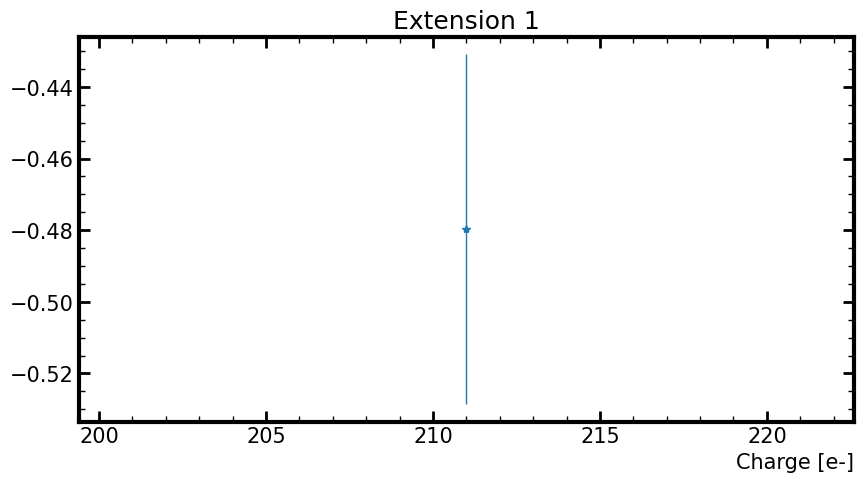

In [52]:
pd.DataFrame(dict_peaks)

list_gains = []
list_err_gains = []
for peak in range(1, len(dict_peaks["#Peak"])):
    # print(peak)
    gain = (dict_peaks["Mean"][peak] - dict_peaks["#Peak"][peak])
    gain_err = dict_peaks["Mean_err"][peak] 

    list_gains.append(gain)
    list_err_gains.append(np.abs(gain_err))
    # print(f"Gain_0{peak}: {round(gain, 3)} +- {round(gain_err, 3)} e-")


fig, axs = plt.subplots(figsize=[10,5])
axs.errorbar(x=dict_peaks["#Peak"][1:], y=list_gains, yerr=list_err_gains, marker = "*", )
# axs.hist(oScan.flatten(), range=(-1,2.5), bins=100, histtype="step")
axs.set_xlabel('Charge [e-]')
axs.set_title(f"Extension {extension}")
# axs.set_yscale('log')

plt.show()

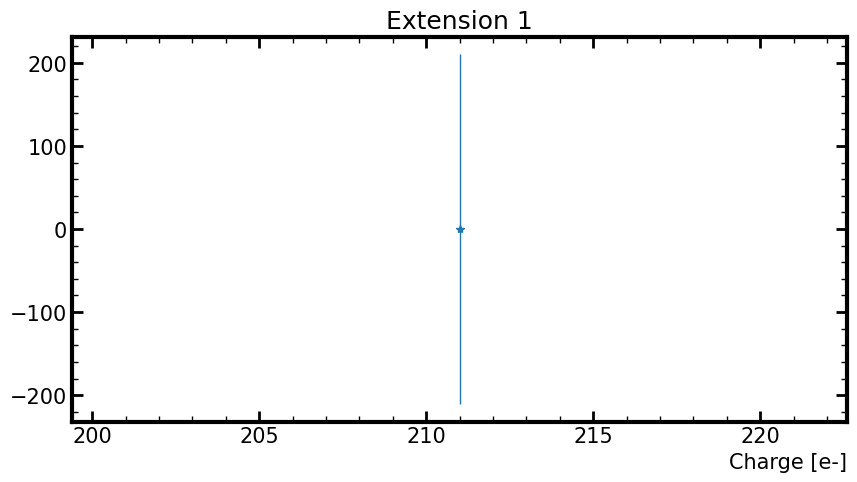

In [53]:
pd.DataFrame(dict_peaks)

peak_0 = dict_peaks["Mean"][0]
# print(peak_0)
list_gains = []
list_err_gains = []
for peak in range(1, len(dict_peaks["#Peak"])):
    # print(peak)
    gain = (dict_peaks["Mean"][peak] - peak_0)/peak
    gain_err = (dict_peaks["Mean_err"][peak] + peak_0)/peak

    list_gains.append(gain)
    list_err_gains.append(np.abs(gain_err))
    # print(f"Gain_0{peak}: {round(gain, 3)} +- {round(gain_err, 3)} e-")


fig, axs = plt.subplots(figsize=[10,5])
axs.errorbar(x=dict_peaks["#Peak"][1:], y=list_gains, yerr=list_err_gains, marker = "*", )
# axs.hist(oScan.flatten(), range=(-1,2.5), bins=100, histtype="step")
axs.set_xlabel('Charge [e-]')
axs.set_title(f"Extension {extension}")
# axs.set_yscale('log')

plt.show()

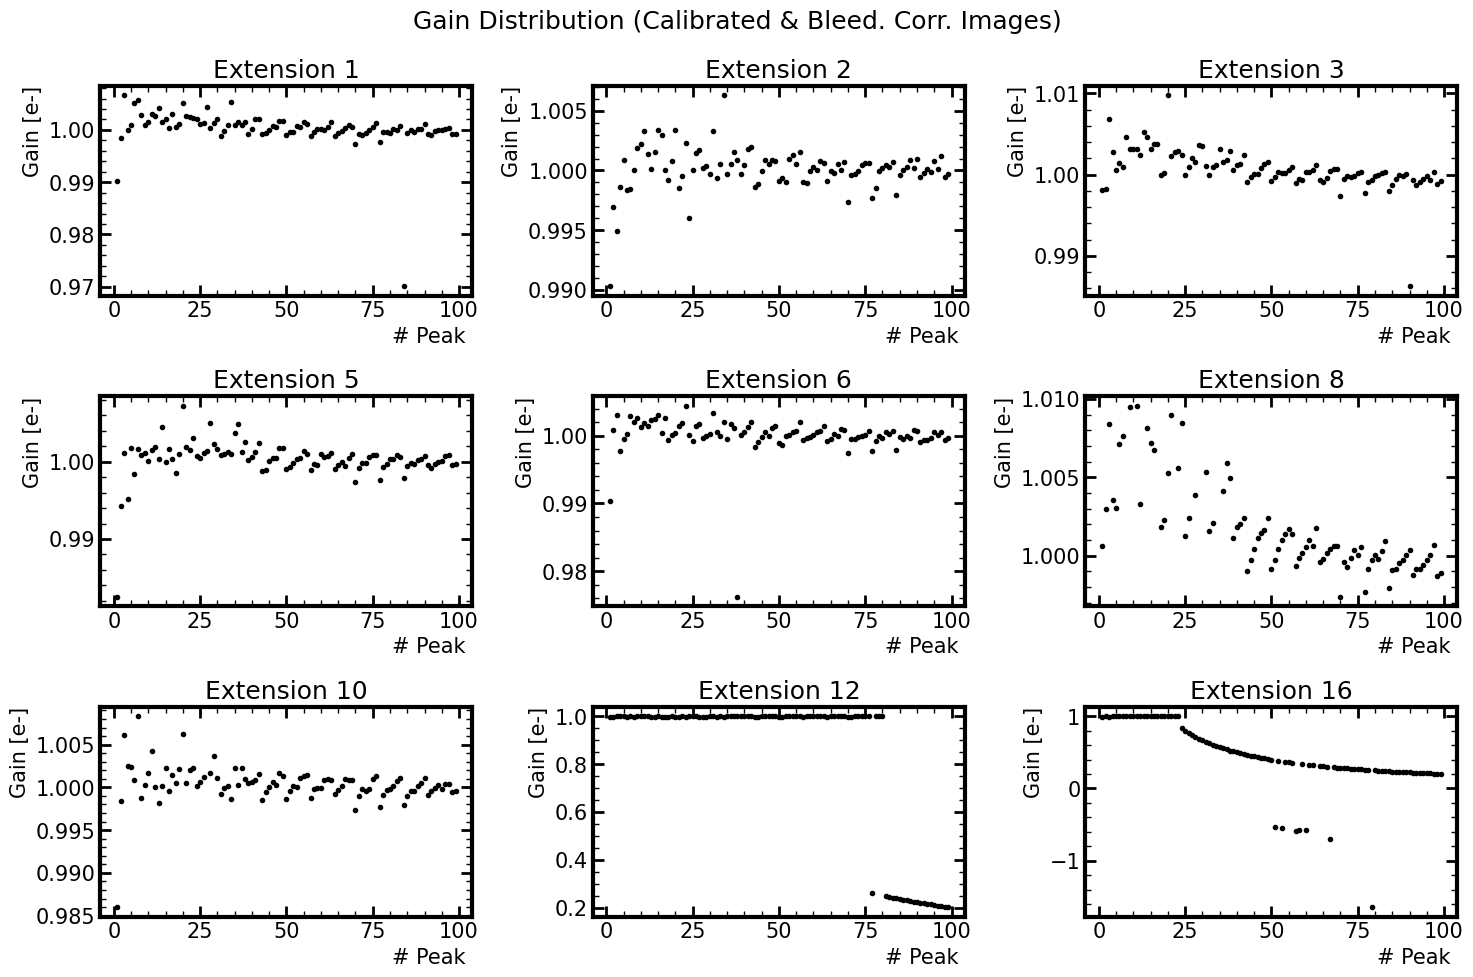

Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <Fit>: Fit data is empty 
Warning in <Fit>: Fit data is empty 
Warning in <Fit>: Fit data is empty 
Warning in <Fit>: Fit data is empty 
Warning in <Fit>: Fit data is empty 
Warning in <Fit>: Fit data is em

In [54]:
path_imgs = ['../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_470.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_471.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_472.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_473.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_474.fits']

# path_imgs = ['../../images/CONNIE_MCM/RUN_213/proc_images/equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_470.fits',
#              '../../images/CONNIE_MCM/RUN_213/proc_images/equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_471.fits',
#              '../../images/CONNIE_MCM/RUN_213/proc_images/equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_472.fits',
#              '../../images/CONNIE_MCM/RUN_213/proc_images/equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_473.fits',
#              '../../images/CONNIE_MCM/RUN_213/proc_images/equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_474.fits']
# extension = 1
x_max = 430
y_max = 500
border = 10

CCD_array = (1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16)
# CCD_arrayOfficial = (1,2,5,6,7,9,14,15,16)
CCD_bad = (4, 7, 9, 11, 13, 14, 15)


fig, axs = plt.subplots(3, 3, figsize=[15, 10])
axes_list = axs.flat
plot_index = 0

for extension in CCD_array:
    if extension in CCD_bad:
        continue

    list_active_area = []
    for path in path_imgs:
        hdu_list = fits.open(path)
        activeArea = hdu_list[extension].data[border:y_max-border, border:x_max] # Without the border
        # oScan = hdu_list[extension].data[border:y_max-border, x_max:]
        header = hdu_list[extension].header
        list_active_area.append(activeArea.flatten())

    data = np.array(list_active_area)

    Bins = 500
    Bins_fit = Bins
    peak = 100
    h3=TH1F("histogram", r"Distribucion del Overscan",Bins_fit, -2, peak+1)

    dict_peaks = {"#Peak": [], "Mean": [], "Mean_err": [], "Sigma": [],  "Sigma_err": []}
    for pixel_value in data.flatten():
        # if not np.ma.is_masked(pixel_value):
        h3.Fill(pixel_value)
        #print(pixel_value)
        
    for peak in range(0, peak):
        val_ref = peak

        value_fit = 0.3
        if peak >= 16:
            value_fit = 0.28

        if peak >= 40:
            value_fit = 0.2
            L_option = "LRNQ"
            # L_option = "RNQ"

        Range_fit_1 = [val_ref - value_fit, val_ref + value_fit]
        fgaus = TF1("gaus1","gaus", Range_fit_1[0], Range_fit_1[1],3) # TF1("nombre", "funcion escrita como en root", min, max, #parametros)
        fgaus.SetParameters(10000, 20, 60) # Establecer parametros iniciales del fit, de manera visual es posible determinarlos como una primera aproximacion


        if peak >= 50:
            h3.Fit(fgaus, L_option)
        else:
            h3.Fit(fgaus, "RNQ")

        mean = fgaus.GetParameters()[1]
        sigma = fgaus.GetParameters()[2]

        mean_err = fgaus.GetParError(1)
        sig_err = fgaus.GetParError(1)

        dict_peaks["#Peak"].append(peak)
        dict_peaks["Mean"].append(mean)
        dict_peaks["Mean_err"].append(mean_err)
        dict_peaks["Sigma"].append(sigma)
        dict_peaks["Sigma_err"].append(sig_err)
    
    peak_0 = dict_peaks["Mean"][0]
    # print(peak_0)
    list_gains = []
    list_err_gains = []
    list_peaks = []
    for peak in range(1, len(dict_peaks["#Peak"])):
        # print(peak)
        gain = (dict_peaks["Mean"][peak] - peak_0)/peak
        gain_err = (dict_peaks["Mean_err"][peak] + peak_0)/peak
        # gain = (dict_peaks["#Peak"][peak] - dict_peaks["Mean"][peak])
        # gain_err = dict_peaks["Mean_err"][peak]/4
        # if gain > 1.01 or gain < 0.9:
        if gain > 1.01:
            continue

        list_gains.append(gain)
        list_err_gains.append(np.abs(gain_err))
        list_peaks.append(peak)
        # print(f"Gain_0{peak}: {round(gain, 3)} +- {round(gain_err, 3)} e-")

    ax = axes_list[plot_index]

    # ax.errorbar(x=dict_peaks["#Peak"][1:], y=list_gains, yerr=list_err_gains, marker = ".", mfc="k", ecolor = "r")
    ax.scatter(list_peaks, list_gains, marker = ".", color="k")
    ax.set_title(f'Extension {extension}')
    ax.set_ylabel('Gain [e-]')
    # ax.set_ylabel('True Peak - Mean Peak [e-]')
    ax.set_xlabel('# Peak ')
    # ax.set_ylim(0.95,)
    plot_index += 1

    if extension == 1:
        list_diff_Ext1 = list_gains
        list_differr_Ext1 = list_err_gains
        list_peaks_Ext1 = dict_peaks["#Peak"][1:]
        

fig.suptitle("Gain Distribution (Calibrated & Bleed. Corr. Images)")
# fig.suptitle("Gain Distribution (Calibrated Images)")
plt.tight_layout()
plt.show()


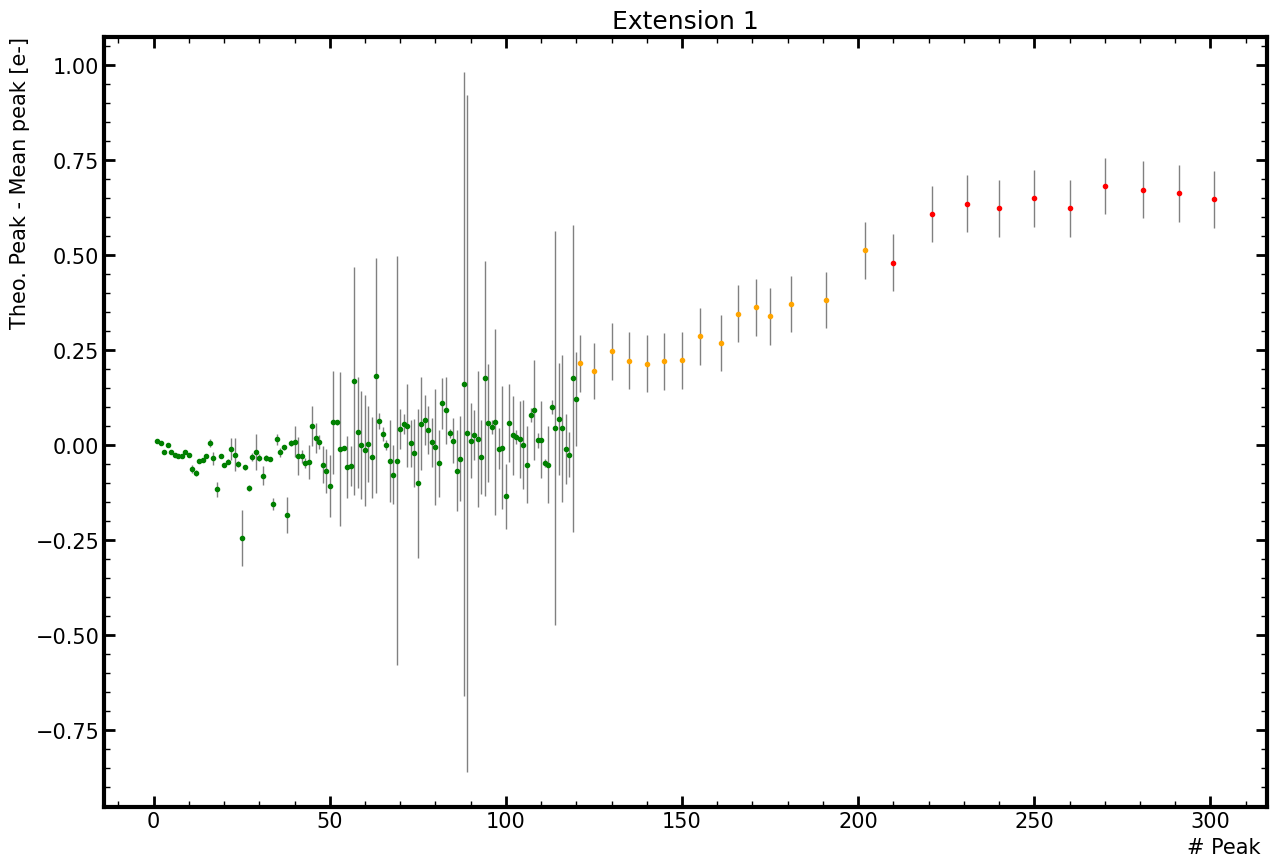

In [480]:
new_peaks = [121, 125, 130, 135, 140, 145, 150, 155, 161, 166, 171, 175, 181, 191, 202]
new_means = [120.7836, 124.8044, 129.7526, 134.7773, 139.7856, 144.7793, 149.7767, 154.7134, 160.7308, 165.6541, 170.6365, 174.6601, 180.6281, 190.6174, 201.4865]
new_meansErr = [0.07486, 0.07486, 0.07486, 0.07486, 0.07486, 0.07486, 0.07486, 0.07486, 0.07486, 0.07486, 0.07486, 0.07486, 0.07486, 0.07486, 0.07486]

new_peaks_W = [210, 221, 231, 240, 250, 260, 270, 281, 291, 301]
new_means_W = [209.5191, 220.3911, 230.3641, 239.3766, 249.35, 259.3764, 269.3175, 280.3267, 290.3371, 300.3521]
new_means_WErr = [0.07486, 0.07486, 0.07486, 0.07486, 0.07486, 0.07486, 0.07486, 0.07486, 0.07486, 0.07486]

list_badArea = []
list_WarArea = []
list_WarAreaErr = []
for index in range(0, len(new_peaks)):
    diff = new_peaks[index] - new_means[index]
    list_badArea.append(diff)
    # list_peaks_Ext1.append(new_peaks[index])
    # list_diff_Ext1.append(diff)

for index in range(0, len(new_peaks_W)):
    diff = new_peaks_W[index] - new_means_W[index]
    list_WarArea.append(diff)

fig, ax = plt.subplots(1,1, figsize = [15,10])
ax.errorbar(x=list_peaks_Ext1, y=list_diff_Ext1, yerr=list_differr_Ext1, marker = ".", mfc="g", mec = "g", ecolor = "gray", linestyle='none')
# ax.scatter(list_peaks_Ext1, list_diff_Ext1, marker = ".", color="g")
ax.errorbar(x=new_peaks, y=list_badArea, yerr=new_meansErr, marker = ".", mfc="orange", mec = "orange", ecolor = "gray", linestyle='none')
# ax.scatter(new_peaks, list_badArea, marker = ".", color="orange")
ax.errorbar(x=new_peaks_W, y=list_WarArea, yerr=new_means_WErr, marker = ".", mfc="r", mec = "r", ecolor = "gray", linestyle='none')
# ax.scatter(new_peaks_W, list_WarArea, marker = ".", color="r")
ax.set_title(f'Extension {1}')
ax.set_ylabel('Theo. Peak - Mean peak [e-]')
ax.set_xlabel('# Peak ')

plt.show()

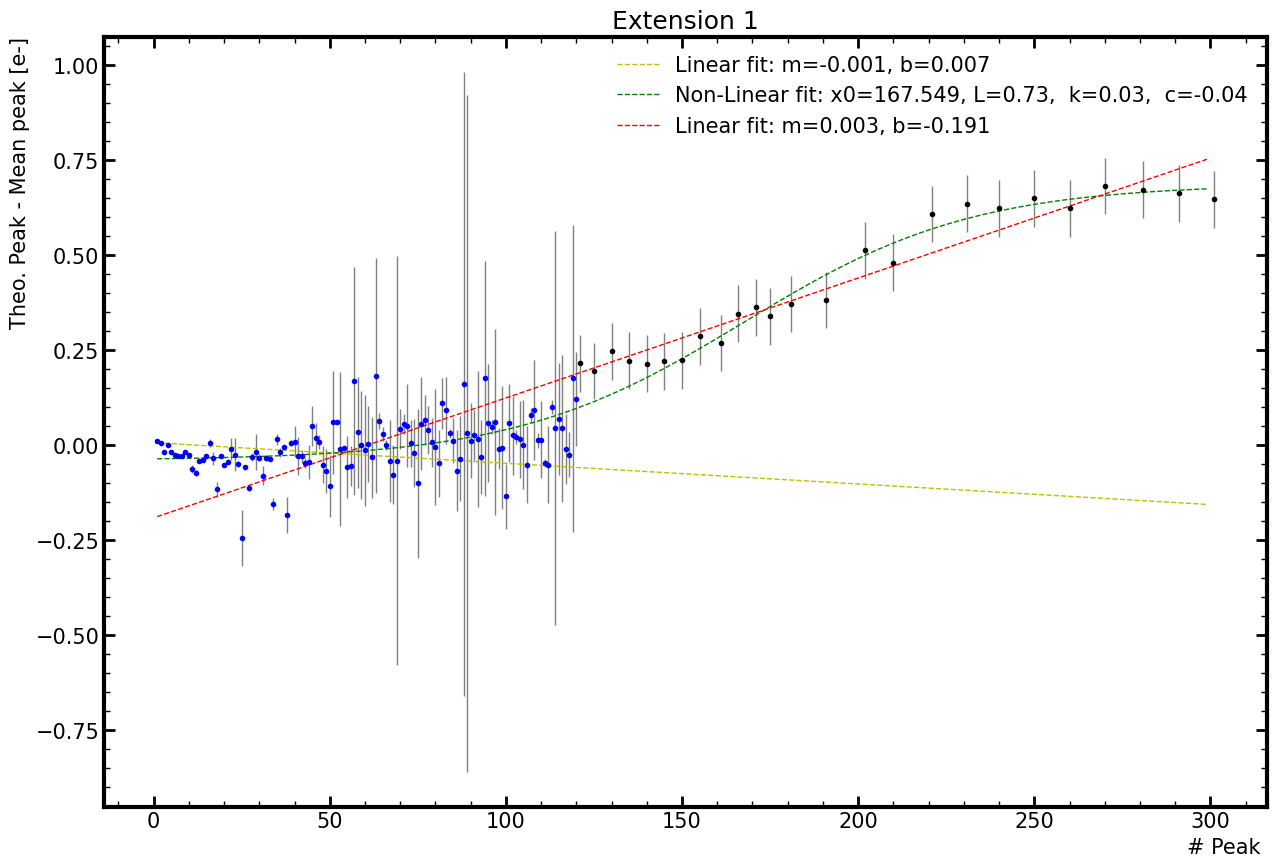

In [555]:
list_badAreas_peaks = []
list_badAreas_diff = []
list_badAreas_diffErr = []
for index in range(0, len(list_badArea)):
    list_badAreas_peaks.append(new_peaks[index])
    list_badAreas_diff.append(list_badArea[index])
    list_badAreas_diffErr.append(new_meansErr[index])

for index in range(0, len(list_WarArea)):
    list_badAreas_peaks.append(new_peaks_W[index])
    list_badAreas_diff.append(list_WarArea[index])
    list_badAreas_diffErr.append(new_means_WErr[index])

list_allAreas_peaks = []
list_allAreas_diff = []
list_allAreas_diffErr = []
for index in range(0, len(list_peaks_Ext1)):
    list_allAreas_peaks.append(list_peaks_Ext1[index])
    list_allAreas_diff.append(list_diff_Ext1[index])
    list_allAreas_diffErr.append(list_differr_Ext1[index])
for index in range(0, len(list_badArea)):
    list_allAreas_peaks.append(new_peaks[index])
    list_allAreas_diff.append(list_badArea[index])
    list_allAreas_diffErr.append(new_meansErr[index])
for index in range(0, len(list_WarArea)):
    list_allAreas_peaks.append(new_peaks_W[index])
    list_allAreas_diff.append(list_WarArea[index])
    list_allAreas_diffErr.append(new_means_WErr[index])

fig, ax = plt.subplots(1,1, figsize = [15,10])
ax.errorbar(x=list_peaks_Ext1, y=list_diff_Ext1, yerr=list_differr_Ext1, marker = ".", mfc="b", mec = "b", ecolor = "gray", linestyle='none')
ax.errorbar(x=list_badAreas_peaks, y=list_badAreas_diff, yerr=list_badAreas_diffErr, marker = ".", mfc="k", mec = "k", ecolor = "gray", linestyle='none')
ax.set_title(f'Extension {1}')
ax.set_ylabel('Theo. Peak - Mean peak [e-]')
ax.set_xlabel('# Peak ')

def line(x, m, b):
    return m*x + b
# Ev = (Ea-a0)/(a1+a0*a2-a2*Ea); 
def nonlin(x, x_0, L, k,c):
    return (L / (1 + np.e**(-k*(x-x_0)))) + c

popt_DM, _ = curve_fit(line, list_peaks_Ext1, list_diff_Ext1, sigma=list_differr_Ext1, maxfev=100000, p0= [1, 1])
popt_DMnonl, _ = curve_fit(nonlin, list_allAreas_peaks, list_allAreas_diff, maxfev=100000)
popt_BA, _ = curve_fit(line, list_badAreas_peaks, list_badAreas_diff, sigma=list_badAreas_diffErr, maxfev=100000, p0= [1, 1])
popt_BAnonl, _ = curve_fit(nonlin, list_badAreas_peaks, list_badAreas_diff, sigma=list_badAreas_diffErr, maxfev=100000, p0=[175,65,1,1])
# dict_diffution_model = {'Alpha' : popt_DM[0], 'Beta' : popt_DM[1]}
# print('Alpha: ', dict_diffution_model['Alpha'], ' Beta: ', dict_diffution_model['Beta'])

popt_DM
fit_range = np.arange(1, 300)
ax.plot(fit_range, line(fit_range, m=popt_DM[0],b=popt_DM[1]), "--y", label = f"Linear fit: m={round(popt_DM[0],3)}, b={round(popt_DM[1],3)}")
ax.plot(fit_range, nonlin(fit_range,x_0=popt_DMnonl[0],  L=popt_DMnonl[1], k=popt_DMnonl[2], c=popt_DMnonl[3]), "--g", 
        label = f"Non-Linear fit: x0={round(popt_DMnonl[0],3)}, L={round(popt_DMnonl[1],2)},  k={round(popt_DMnonl[2],2)},  c={round(popt_DMnonl[3],2)}")
ax.plot(fit_range, line(fit_range, m=popt_BA[0],b=popt_BA[1]), "--r", label = f"Linear fit: m={round(popt_BA[0],3)}, b={round(popt_BA[1],3)}")
plt.legend()
plt.show()

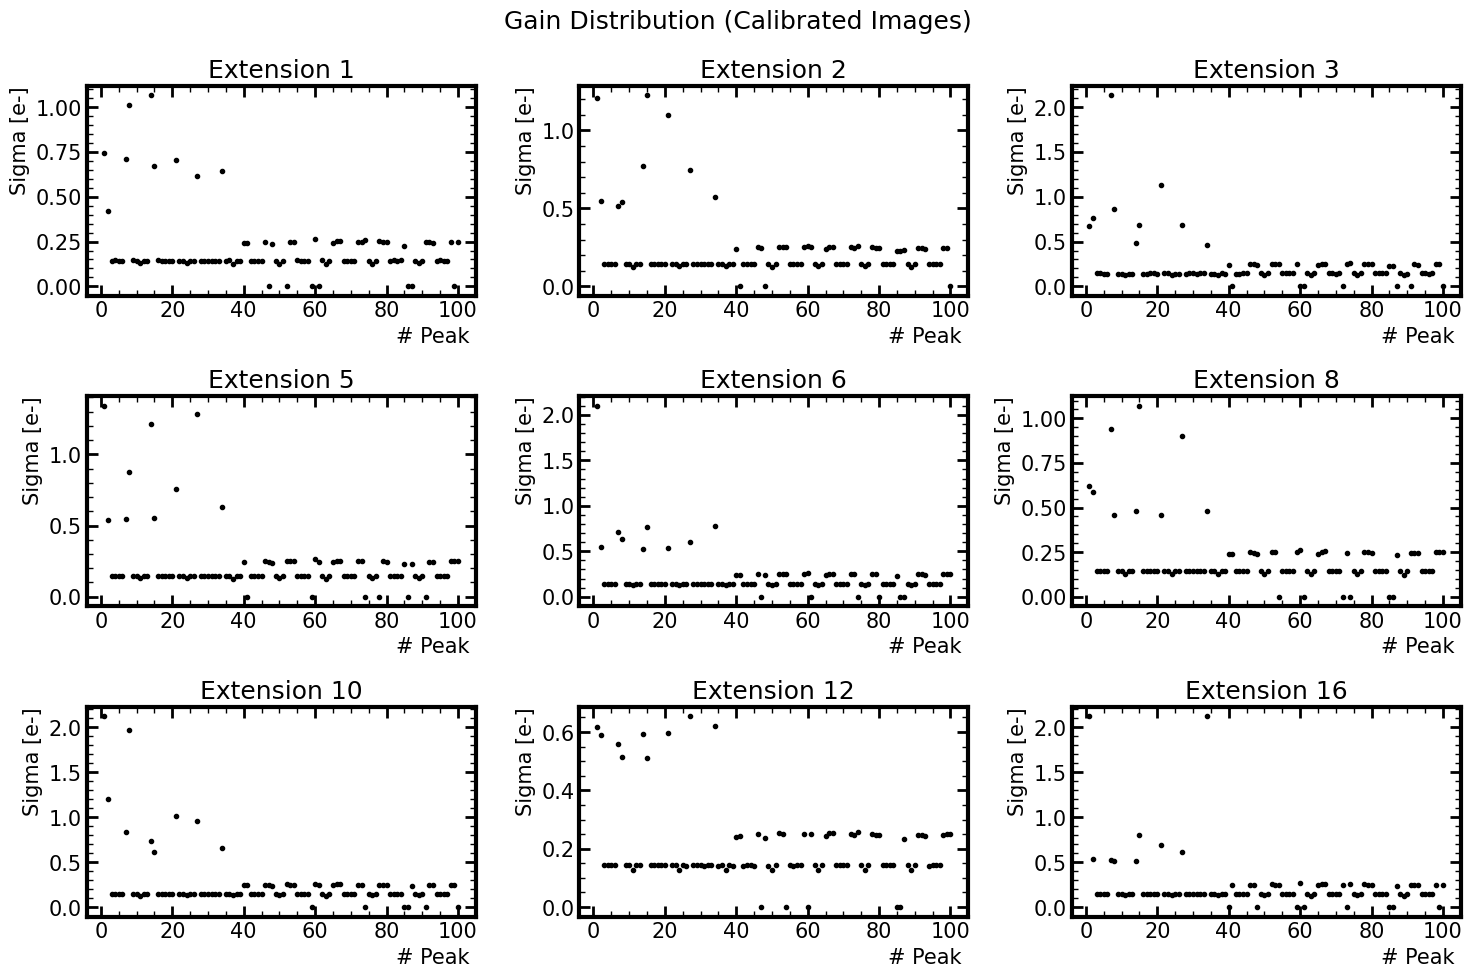

Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).


In [81]:
# path_imgs = ['../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_470.fits',
#              '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_471.fits',
#              '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_472.fits',
#              '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_473.fits',
#              '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_474.fits']

path_imgs = ['../../images/CONNIE_MCM/RUN_213/proc_images/equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_470.fits',
             '../../images/CONNIE_MCM/RUN_213/proc_images/equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_471.fits',
             '../../images/CONNIE_MCM/RUN_213/proc_images/equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_472.fits',
             '../../images/CONNIE_MCM/RUN_213/proc_images/equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_473.fits',
             '../../images/CONNIE_MCM/RUN_213/proc_images/equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_474.fits']
extension = 1
x_max = 430
y_max = 500
border = 10

CCD_array = (1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16)
# CCD_arrayOfficial = (1,2,5,6,7,9,14,15,16)
CCD_bad = (4, 7, 9, 11, 13, 14, 15)


fig, axs = plt.subplots(3, 3, figsize=[15, 10])
axes_list = axs.flat
plot_index = 0

for extension in CCD_array:
    if extension in CCD_bad:
        continue

    list_active_area = []
    for path in path_imgs:
        hdu_list = fits.open(path)
        activeArea = hdu_list[extension].data[border:y_max-border, border:x_max] # Without the border
        # oScan = hdu_list[extension].data[border:y_max-border, x_max:]
        header = hdu_list[extension].header
        list_active_area.append(activeArea.flatten())

    data = np.array(list_active_area)

    Bins = 400
    Bins_fit = Bins
    peak = 101
    h3=TH1F("histogram", r"Distribucion del Overscan",Bins_fit, -2, peak+1)

    dict_peaks = {"#Peak": [], "Mean": [], "Mean_err": [], "Sigma": [],  "Sigma_err": []}
    for pixel_value in data.flatten():
        # if not np.ma.is_masked(pixel_value):
        h3.Fill(pixel_value)
        #print(pixel_value)
        
    for peak in range(0, peak):
        val_ref = peak

        value_fit = 0.3
        if peak >= 16:
            value_fit = 0.28

        if peak >= 40:
            value_fit = 0.2
            L_option = "LRNQ"
            # L_option = "RNQ"

        Range_fit_1 = [val_ref - value_fit, val_ref + value_fit]
        fgaus = TF1("gaus1","gaus", Range_fit_1[0], Range_fit_1[1],3) # TF1("nombre", "funcion escrita como en root", min, max, #parametros)
        fgaus.SetParameters(10000, 20, 60) # Establecer parametros iniciales del fit, de manera visual es posible determinarlos como una primera aproximacion


        if peak >= 50:
            h3.Fit(fgaus, L_option)
        else:
            h3.Fit(fgaus, "RNQ")

        mean = fgaus.GetParameters()[1]
        sigma = fgaus.GetParameters()[2]

        mean_err = fgaus.GetParError(1)
        sig_err = fgaus.GetParError(1)

        dict_peaks["#Peak"].append(peak)
        dict_peaks["Mean"].append(mean)
        dict_peaks["Mean_err"].append(mean_err)
        dict_peaks["Sigma"].append(sigma)
        dict_peaks["Sigma_err"].append(sig_err)
    
    peak_0 = dict_peaks["Mean"][0]
    # print(peak_0)
    list_gains = []
    list_err_gains = []
    for peak in range(1, len(dict_peaks["#Peak"])):
        # print(peak)
        gain = dict_peaks["Sigma"][peak]
        gain_err = dict_peaks["Sigma_err"][peak]

        list_gains.append(gain)
        list_err_gains.append(np.abs(gain_err))
        # print(f"Gain_0{peak}: {round(gain, 3)} +- {round(gain_err, 3)} e-")

    ax = axes_list[plot_index]

    # ax.errorbar(x=dict_peaks["#Peak"][1:], y=list_gains, yerr=list_err_gains, marker = ".", mfc="k", ecolor = "r")
    ax.scatter(dict_peaks["#Peak"][1:], list_gains, marker = ".", color="k")
    ax.set_title(f'Extension {extension}')
    ax.set_ylabel('Sigma [e-]')
    ax.set_xlabel('# Peak ')
    plot_index += 1

# fig.suptitle("Sigma Distribution (Calibrated & Bleed. Corr. Images)")
fig.suptitle("Gain Distribution (Calibrated Images)")
plt.tight_layout()
plt.show()


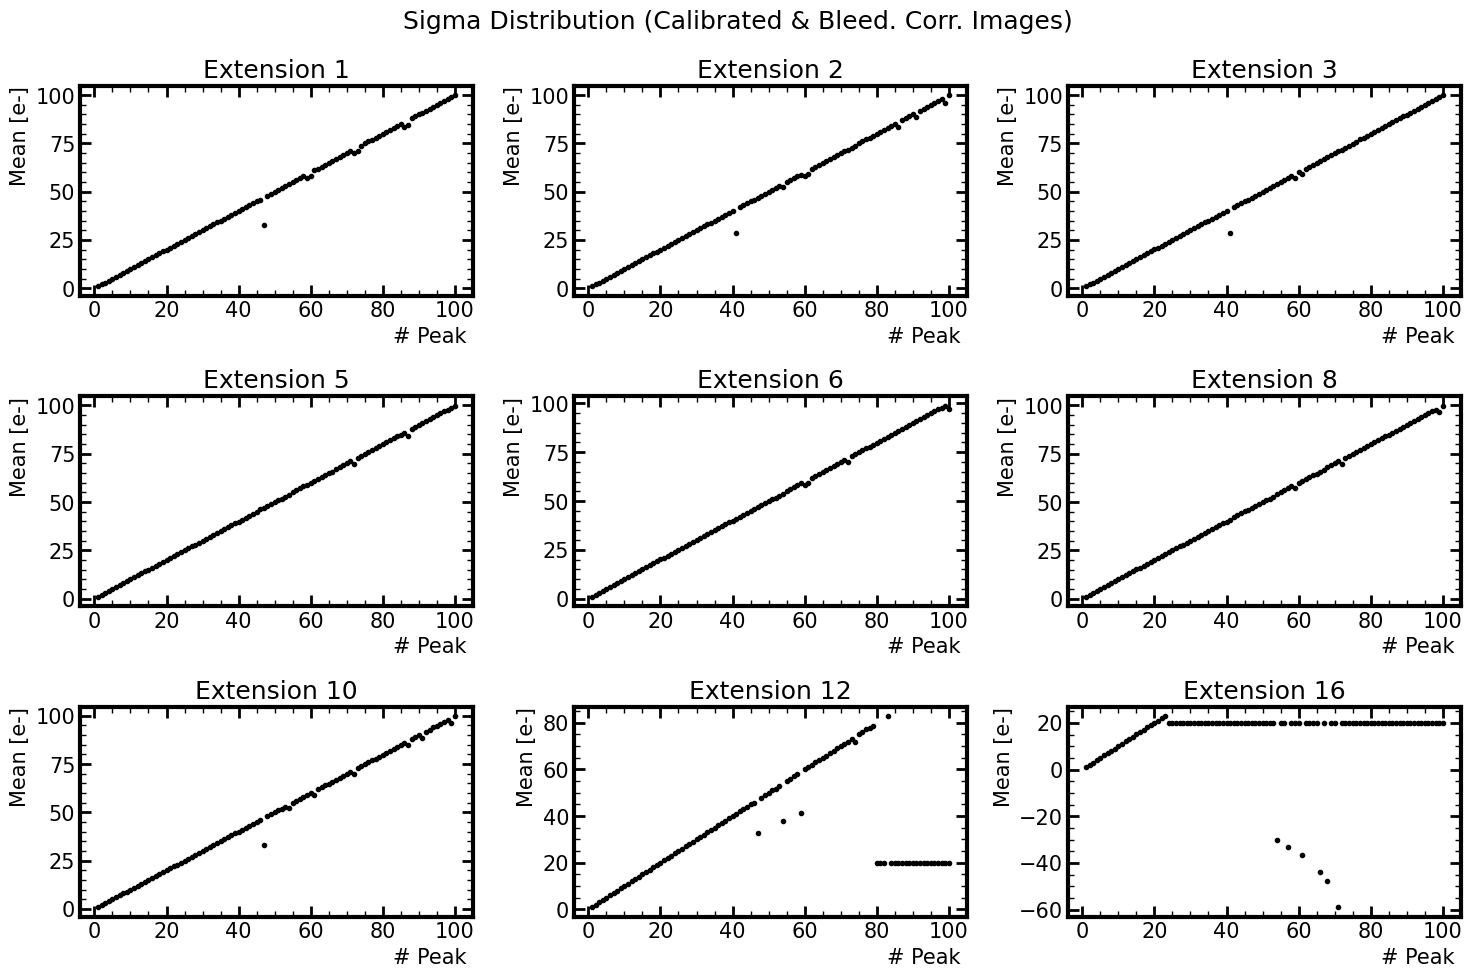

Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
Warning in <Fit>: Fit data is empty 
Warning in <Fit>: Fit data is empty 
Warning in <Fit>: Fit data is empty 
Warning in <Fit>: Fit data is empty 
Warning in <Fit>: Fit data is empty 
Warning in <Fit>: Fit data is em

In [85]:
path_imgs = ['../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_470.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_471.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_472.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_473.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_474.fits']

# path_imgs = ['../../images/CONNIE_MCM/RUN_213/proc_images/equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_470.fits',
#              '../../images/CONNIE_MCM/RUN_213/proc_images/equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_471.fits',
#              '../../images/CONNIE_MCM/RUN_213/proc_images/equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_472.fits',
#              '../../images/CONNIE_MCM/RUN_213/proc_images/equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_473.fits',
#              '../../images/CONNIE_MCM/RUN_213/proc_images/equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_474.fits']


x_max = 430
y_max = 500
border = 10

CCD_array = (1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16)
# CCD_arrayOfficial = (1,2,5,6,7,9,14,15,16)
CCD_bad = (4, 7, 9, 11, 13, 14, 15)


fig, axs = plt.subplots(3, 3, figsize=[15, 10])
axes_list = axs.flat
plot_index = 0

for extension in CCD_array:
    if extension in CCD_bad:
        continue

    list_active_area = []
    for path in path_imgs:
        hdu_list = fits.open(path)
        activeArea = hdu_list[extension].data[border:y_max-border, border:x_max] # Without the border
        # oScan = hdu_list[extension].data[border:y_max-border, x_max:]
        header = hdu_list[extension].header
        list_active_area.append(activeArea.flatten())

    data = np.array(list_active_area)

    Bins = 400
    Bins_fit = Bins
    peak = 101
    h3=TH1F("histogram", r"Distribucion del Overscan",Bins_fit, -2, peak+1)

    dict_peaks = {"#Peak": [], "Mean": [], "Mean_err": [], "Sigma": [],  "Sigma_err": []}
    for pixel_value in data.flatten():
        # if not np.ma.is_masked(pixel_value):
        h3.Fill(pixel_value)
        #print(pixel_value)
        
    for peak in range(0, peak):
        val_ref = peak

        value_fit = 0.3
        if peak >= 16:
            value_fit = 0.28

        if peak >= 40:
            value_fit = 0.2
            L_option = "LRNQ"
            # L_option = "RNQ"

        Range_fit_1 = [val_ref - value_fit, val_ref + value_fit]
        fgaus = TF1("gaus1","gaus", Range_fit_1[0], Range_fit_1[1],3) # TF1("nombre", "funcion escrita como en root", min, max, #parametros)
        fgaus.SetParameters(10000, 20, 60) # Establecer parametros iniciales del fit, de manera visual es posible determinarlos como una primera aproximacion


        if peak >= 50:
            h3.Fit(fgaus, L_option)
        else:
            h3.Fit(fgaus, "RNQ")

        mean = fgaus.GetParameters()[1]
        sigma = fgaus.GetParameters()[2]

        mean_err = fgaus.GetParError(1)
        sig_err = fgaus.GetParError(1)

        dict_peaks["#Peak"].append(peak)
        dict_peaks["Mean"].append(mean)
        dict_peaks["Mean_err"].append(mean_err)
        dict_peaks["Sigma"].append(sigma)
        dict_peaks["Sigma_err"].append(sig_err)
    
    peak_0 = dict_peaks["Mean"][0]
    # print(peak_0)
    list_gains = []
    list_err_gains = []
    for peak in range(1, len(dict_peaks["#Peak"])):
        # print(peak)
        gain = dict_peaks["Mean"][peak]
        gain_err = dict_peaks["Mean_err"][peak]

        list_gains.append(gain)
        list_err_gains.append(np.abs(gain_err))
        # print(f"Gain_0{peak}: {round(gain, 3)} +- {round(gain_err, 3)} e-")

    ax = axes_list[plot_index]

    # ax.errorbar(x=dict_peaks["#Peak"][1:], y=list_gains, yerr=list_err_gains, marker = ".", mfc="k", ecolor = "r")
    ax.scatter(dict_peaks["#Peak"][1:], list_gains, marker = ".", color="k")
    ax.set_title(f'Extension {extension}')
    ax.set_ylabel('Mean [e-]')
    ax.set_xlabel('# Peak ')
    plot_index += 1

fig.suptitle("Sigma Distribution (Calibrated & Bleed. Corr. Images)")
# fig.suptitle("Gain Distribution (Calibrated Images)")
plt.tight_layout()
plt.show()


In [86]:
path_imgs = ['../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_470.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_471.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_472.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_473.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_474.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_475.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_476.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_477.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_478.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_479.fits']
extension = 1
x_max = 430
y_max = 500
border = 10

list_active_area = []
for path in path_imgs:
    hdu_list = fits.open(path)
    
    activeArea = hdu_list[extension].data[border:y_max-border, border:x_max] # Without the border
    # oScan = hdu_list[extension].data[border:y_max-border, x_max:]
    header = hdu_list[extension].header

    list_active_area.append(activeArea.flatten())

combined_data = np.array(list_active_area)
# print("Shape of combined data:", combined_data.shape)

Bins = 70
Bins_fit = Bins
# Range_fit = [-100, 400]

# Ranges 0 to 120 (bins 850), 121 to 200
range_peak_init = 120
range_peak_final = 125

theo_peak = 320
diff = 0.1
true_peak = theo_peak - diff

data = combined_data.flatten()
h3=TH1F("histogram", f"Active Area Charge Distribution (Ext {extension})",Bins_fit, range_peak_init-2, range_peak_final+2)
# h3.AddDirectory(False)

c1=TCanvas()
c1.SetLogy()
c1.SetGrid()
h3.SetStats(0)
h3.GetXaxis().SetTitle("Charge [e-]")
h3.Draw()

# leg = TLegend(0.5, 0.7, 0.9, 0.9)
# leg.AddEntry(fgaus, "Ajustes gaussianos", "L")
# leg.Draw()

dict_peaks = {"#Peak": [], "Mean": [], "Mean_err": [], "Sigma": [],  "Sigma_err": [], "Chi2": [], "NDF":[], "Prob":[],
               "Gain[P-P0]":[], "Gain[Pn+1-Pn]":[]}
for pixel_value in data.flatten():
    # if not np.ma.is_masked(pixel_value):
    h3.Fill(pixel_value)
    #print(pixel_value)
    
# for peak in range(0, peak):
for peak in range(range_peak_init, range_peak_final+1):
    val_ref = peak

    value_fit = [0.3, 0.3]
    if peak == 0:
        value_fit = [0.6, 0.5]
    if peak >= 16:
        value_fit = [0.28, 0.28]

    if peak >= 40:
        value_fit = [0.37, 0.37]
        # L_option = "LRNQ"
        L_option = "RNQ"

    Range_fit_1 = [val_ref - value_fit[0], val_ref + value_fit[1]]
    fgaus = TF1("gaus1","gaus", Range_fit_1[0], Range_fit_1[1],3) # TF1("nombre", "funcion escrita como en root", min, max, #parametros)
    fgaus.SetParameters(10, true_peak, 1) # Establecer parametros iniciales del fit, de manera visual es posible determinarlos como una primera aproximacion

    if peak >= 50:
        h3.Fit(fgaus, L_option)

    else:
        h3.Fit(fgaus, "RNQ")
        
    fgaus.Draw("same")

    high = fgaus.GetParameters()[0]
    en_scape = theo_peak
    line1 = TLine(en_scape, 0, en_scape, high)
    line1.SetLineColor(1)
    line1.SetLineWidth(2)
    line1.Draw()

    mean = fgaus.GetParameters()[1]
    sigma = fgaus.GetParameters()[2]

    mean_err = fgaus.GetParError(1)
    sig_err = fgaus.GetParError(2)

    chi2 = fgaus.GetChisquare()
    ndf = fgaus.GetNDF()
    prob = fgaus.GetProb()

    dict_peaks["#Peak"].append(peak)
    dict_peaks["Mean"].append(mean)
    dict_peaks["Mean_err"].append(mean_err)
    dict_peaks["Sigma"].append(sigma)
    dict_peaks["Sigma_err"].append(sig_err)
    dict_peaks["Chi2"].append(chi2)
    dict_peaks["NDF"].append(ndf)
    dict_peaks["Prob"].append(prob)


leg = TLegend(0.6,0.75,0.9,0.9)
# leg.AddEntry(h3, "Data", "PL")
# leg.AddEntry(h3, r"cal = 196.881 \pm 7.802 ADU/e")
leg.AddEntry(fgaus, f"Gauss Fit: {round(dict_peaks['Mean'][-1],2)} e-", "L")
leg.AddEntry(line1, f"Theoretical Value: {en_scape} e-", "L")
# leg.Draw()

c1.Draw()

# display(pd.DataFrame(dict_peaks))

peak_0 = dict_peaks["Mean"][0]
err_peak_0 = dict_peaks["Mean_err"][0]

# print(peak_0)
list_gains = []
list_err_gains = []

for peak in range(0, len(dict_peaks["#Peak"])):
    # print(peak)
    # print(dict_peaks["Mean"][peak])
    if peak == 0:
        gain = 0
        gain_err = 0
        dict_peaks["Gain[P-P0]"].append(gain)
        dict_peaks["Gain[Pn+1-Pn]"].append(gain)
        continue

    # gain = (dict_peaks["Mean"][peak] - peak_0)/dict_peaks["#Peak"][peak]
    # gain_err = np.sqrt((dict_peaks["Mean_err"][peak])**2 + (err_peak_0)**2)/dict_peaks["#Peak"][peak]

    gain = (dict_peaks["Mean"][peak])/dict_peaks["#Peak"][peak]
    gain_err = (dict_peaks["Mean_err"][peak])/dict_peaks["#Peak"][peak]

    gain_n = dict_peaks["Mean"][peak] - dict_peaks["Mean"][peak-1] 

    dict_peaks["Gain[P-P0]"].append(gain)
    dict_peaks["Gain[Pn+1-Pn]"].append(gain_n)

    list_gains.append(gain)
    list_err_gains.append(np.abs(gain_err))
    # print(f"Gain_0{dict_peaks['#Peak'][peak]}: {round(gain, 3)} +- {round(gain_err, 3)} e-")
    # print(f"Gain_0to{int(dict_peaks['#Peak'][peak])}: {round(gain, 5)} e-")

display(pd.DataFrame(dict_peaks))


,#Peak,Mean,Mean_err,Sigma,Sigma_err,Chi2,NDF,Prob,Gain[P-P0],Gain[Pn+1-Pn]
0,120,119.778478,0.072484,0.130665,0.063378,2.960659,1,0.085313,0.000000,0.000000
1,121,120.735891,0.135836,0.279514,0.101715,0.249408,3,0.969245,0.997817,0.957413
2,122,121.742067,0.137041,0.225308,0.117376,2.308300,3,0.510933,0.997886,1.006176
3,123,122.883158,0.063544,0.239127,0.077188,1.485348,2,0.475840,0.999050,1.141091
4,124,123.861893,0.026785,0.131732,0.030265,1.256912,2,0.533415,0.998886,0.978735
5,125,124.847126,0.086706,0.194323,0.062182,0.213162,2,0.898902,0.998777,0.985233


Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).


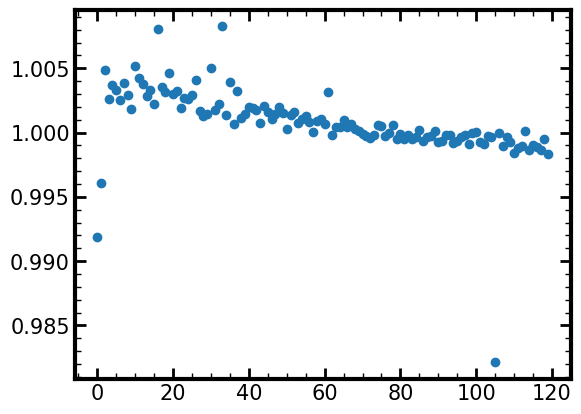

In [72]:
plt.scatter(range(0, len(list_gains)), list_gains)

In [47]:
path_imgs = ['../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_470.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_471.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_472.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_473.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_474.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_475.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_476.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_477.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_478.fits',
             '../../images/CONNIE_MCM/RUN_213/corr_calib_equalized_demuxed_runID213_MCM_NROW500_ANSAMP500_EXP0_479.fits']
extension = 1
x_max = 430
y_max = 500
border = 10

list_active_area = []
for path in path_imgs:
    hdu_list = fits.open(path)
    
    activeArea = hdu_list[extension].data[border:y_max-border, border:x_max] # Without the border
    # oScan = hdu_list[extension].data[border:y_max-border, x_max:]
    header = hdu_list[extension].header

    list_active_area.append(activeArea.flatten())

combined_data = np.array(list_active_area)
# print("Shape of combined data:", combined_data.shape)

Bins = 100 #850
Bins_fit = Bins
# Range_fit = [-100, 400]

range_peak_init = 120
range_peak_final = 140

theo_peak = 320
diff = 0.7
true_peak = theo_peak - diff

data = combined_data.flatten()
h3=TH1F("histogram", f"Active Area Charge Distribution (Ext {extension})",Bins_fit, range_peak_init-2, range_peak_final+2)
# h3.AddDirectory(False)

c1=TCanvas()
c1.SetLogy()
c1.SetGrid()
h3.SetStats(0)
h3.GetXaxis().SetTitle("Charge [e-]")
h3.Draw()

# leg = TLegend(0.5, 0.7, 0.9, 0.9)
# leg.AddEntry(fgaus, "Ajustes gaussianos", "L")
# leg.Draw()

dict_peaks = {"#Peak": [], "Mean": [], "Mean_err": [], "Sigma": [],  "Sigma_err": [], "Chi2": [], "NDF":[], "Prob":[]}
for pixel_value in data.flatten():
    # if not np.ma.is_masked(pixel_value):
    h3.Fill(pixel_value)
    #print(pixel_value)
    
# for peak in range(0, peak):
for peak in range(range_peak_init, range_peak_final+1):
    val_ref = peak

    value_fit = [0.37, 0.37]
    # L_option = "LRNQ"
    L_option = "RNQ"

    Range_fit_1 = [val_ref - value_fit[0], val_ref + value_fit[1]]
    fgaus = TF1("gaus1","gaus", Range_fit_1[0], Range_fit_1[1],3) # TF1("nombre", "funcion escrita como en root", min, max, #parametros)
    fgaus.SetParameters(10, true_peak, 1) # Establecer parametros iniciales del fit, de manera visual es posible determinarlos como una primera aproximacion

    h3.Fit(fgaus, L_option)
        
    fgaus.Draw("same")

    high = fgaus.GetParameters()[0]
    en_scape = theo_peak
    line1 = TLine(en_scape, 0, en_scape, high)
    line1.SetLineColor(1)
    line1.SetLineWidth(2)
    line1.Draw()

    mean = fgaus.GetParameters()[1]
    sigma = fgaus.GetParameters()[2]

    mean_err = fgaus.GetParError(1)
    sig_err = fgaus.GetParError(1)

    chi2 = fgaus.GetChisquare()
    ndf = fgaus.GetNDF()
    prob = fgaus.GetProb()

    dict_peaks["#Peak"].append(peak)
    dict_peaks["Mean"].append(mean)
    dict_peaks["Mean_err"].append(mean_err)
    dict_peaks["Sigma"].append(sigma)
    dict_peaks["Sigma_err"].append(sig_err)
    dict_peaks["Chi2"].append(chi2)
    dict_peaks["NDF"].append(ndf)
    dict_peaks["Prob"].append(prob)


leg = TLegend(0.6,0.75,0.9,0.9)
# leg.AddEntry(h3, "Data", "PL")
# leg.AddEntry(h3, r"cal = 196.881 \pm 7.802 ADU/e")
leg.AddEntry(fgaus, f"Gauss Fit: {round(dict_peaks['Mean'][-1],2)} e-", "L")
leg.AddEntry(line1, f"Theoretical Value: {en_scape} e-", "L")
leg.Draw()

c1.Draw()

display(pd.DataFrame(dict_peaks))

peak_0 = dict_peaks["Mean"][0]
# print(peak_0)
list_gains = []
list_err_gains = []

for peak in range(1, len(dict_peaks["#Peak"])):
    # print(peak)
    # print(dict_peaks["Mean"][peak])
    gain = (dict_peaks["Mean"][peak])/dict_peaks["#Peak"][peak]
    gain_err = (dict_peaks["Mean_err"][peak])/dict_peaks["#Peak"][peak]

    list_gains.append(gain)
    list_err_gains.append(np.abs(gain_err))
    # print(f"Gain_0{dict_peaks['#Peak'][peak]}: {round(gain, 3)} +- {round(gain_err, 3)} e-")
    print(f"Gain_0to{int(dict_peaks['#Peak'][peak])}: {round(gain, 5)} e- \n")


,#Peak,Mean,Mean_err,Sigma,Sigma_err,Chi2,NDF,Prob
0,120,116.340561,0.921762,0.774905,0.921762,1.239036e+00,0,0.000000
1,121,120.631102,0.502977,0.326747,0.502977,5.698172e-07,0,0.000000
2,122,121.806173,0.082817,0.217676,0.082817,4.100036e-06,0,0.000000
3,123,122.886084,0.059815,0.259721,0.059815,1.222114e-05,0,0.000000
4,124,123.854729,0.027434,0.165459,0.027434,1.647017e+00,1,0.199365
5,125,124.898067,0.075939,0.173822,0.075939,2.612819e-06,0,0.000000
6,126,125.521911,1.012471,0.332369,1.012471,3.366536e-07,0,0.000000
7,127,126.836841,0.636557,0.118503,0.636557,5.970836e-10,0,0.000000
8,128,127.866308,0.057250,0.202350,0.057250,3.561540e-07,0,0.000000
9,129,128.855308,0.070647,0.252854,0.070647,2.036440e-07,0,0.000000


Gain_0to121: 0.99695 e- 

Gain_0to122: 0.99841 e- 

Gain_0to123: 0.99907 e- 

Gain_0to124: 0.99883 e- 

Gain_0to125: 0.99918 e- 

Gain_0to126: 0.99621 e- 

Gain_0to127: 0.99872 e- 

Gain_0to128: 0.99896 e- 

Gain_0to129: 0.99888 e- 

Gain_0to130: 0.99773 e- 

Gain_0to131: 0.99942 e- 

Gain_0to132: 0.99931 e- 

Gain_0to133: 0.99734 e- 

Gain_0to134: 0.99846 e- 

Gain_0to135: 0.99778 e- 

Gain_0to136: 0.99805 e- 

Gain_0to137: 0.99694 e- 

Gain_0to138: 0.9992 e- 

Gain_0to139: 0.99461 e- 

Gain_0to140: 0.99886 e- 



Warning in <TROOT::Append>: Replacing existing TH1: histogram (Potential memory leak).
